In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


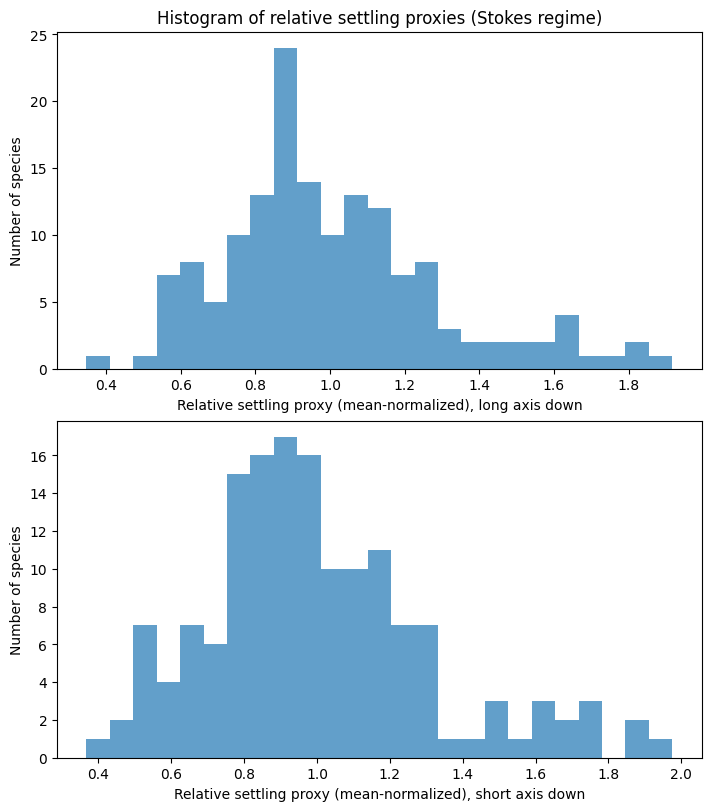

Wrote: ../../Results/Volume/Volume_with_terminal_velocity.csv
Wrote: ../../Results/Volume/terminal_velocity_histograms.svg


In [2]:


def add_terminal_velocity_columns(
    df: pd.DataFrame,
    length_col: str = "avg_length",   # full axis (diameter) in µm
    width_col: str = "avg_width",     # full axis (diameter) in µm
    vol_col: str = "avg_volume_estimated",  # µm^3, consistent with diameter-based prolate volume
    use_semiaxes: bool = False
) -> pd.DataFrame:
    """
    Computes Stokes-regime *settling-speed proxies* for a prolate spheroid in two limiting orientations:
      - long axis down (streamlined; motion parallel to symmetry axis)
      - short axis down (broadside; motion perpendicular to symmetry axis)

    Notes:
    - This returns a proxy proportional to terminal velocity. It intentionally omits constants
      like (rho_p - rho_f)*g/(6*pi*mu) since you are doing relative comparisons and mean-normalizing.
    - If your length/width are diameters (as in your dataset), you may keep use_semiaxes=False
      for continuity. Setting use_semiaxes=True rescales the raw proxy by a constant factor only
      (relative/mean-normalized values remain the same).
    """
    out = df.copy()

    L = out[length_col].astype(float).to_numpy()
    W = out[width_col].astype(float).to_numpy()
    V = out[vol_col].astype(float).to_numpy()

    a = L / 2.0 if use_semiaxes else L.copy()  # semimajor (or diameter if False)
    c = W / 2.0 if use_semiaxes else W.copy()  # semiminor (or diameter if False)

    # Ensure prolate assumption (a >= c). If any rows violate it, swap for computation.
    swap = c > a
    if np.any(swap):
        a2 = a.copy()
        c2 = c.copy()
        a2[swap], c2[swap] = c[swap], a[swap]
        a, c = a2, c2

    # Identify spheres/near-spheres robustly
    sphere = np.isclose(a, c, rtol=1e-12, atol=0.0)
    nons = ~sphere

    # Allocate arrays
    e = np.full_like(a, np.nan, dtype=float)
    Xa = np.full_like(a, np.nan, dtype=float)
    Ya = np.full_like(a, np.nan, dtype=float)
    tv_long = np.full_like(V, np.nan, dtype=float)
    tv_short = np.full_like(V, np.nan, dtype=float)

    # Prolate spheroid eccentricity: e = sqrt(1 - (c/a)^2)
    ratio = np.clip(c[nons] / a[nons], 0.0, 1.0)
    e_n = np.sqrt(np.clip(1.0 - ratio**2, 0.0, 1.0))
    e_clip = np.clip(e_n, 0.0, 1.0 - 1e-15)  # avoid log singularity at e=1

    log_term = np.log((1.0 + e_clip) / (1.0 - e_clip))

    # Perrin-type factors used in your formula
    Xa_n = (8.0 / 3.0) * e_clip**3 / (-2.0 * e_clip + (1.0 + e_clip**2) * log_term)
    Ya_n = (16.0 / 3.0) * e_clip**3 / ( 2.0 * e_clip + (3.0 * e_clip**2 - 1.0) * log_term)

    e[nons] = e_n
    Xa[nons] = Xa_n
    Ya[nons] = Ya_n

    # Proxy settling speeds (constants omitted)
    # Sphere limiting proxy (consistent with your existing approach)
    tv_long[sphere] = V[sphere] / a[sphere]
    tv_short[sphere] = V[sphere] / a[sphere]

    tv_long[nons] = V[nons] / (a[nons] * Xa_n)
    tv_short[nons] = V[nons] / (a[nons] * Ya_n)

    # Mean-normalized (dimensionless) versions
    tv_rel_long = tv_long / np.nanmean(tv_long)
    tv_rel_short = tv_short / np.nanmean(tv_short)

    # Attach columns (keep names explicit for downstream R work)
    out["a_used"] = a
    out["c_used"] = c
    out["aspect_ratio_LW"] = L / W
    out["eccentricity_e"] = e
    out["Xa_long_axis_aligned"] = Xa
    out["Ya_long_axis_perp"] = Ya

    out["tv_proxy_long_axis_down"] = tv_long
    out["tv_proxy_short_axis_down"] = tv_short
    out["tv_rel_long_axis_down"] = tv_rel_long
    out["tv_rel_short_axis_down"] = tv_rel_short

    # A couple of handy derived quantities
    out["tv_ratio_long_over_short"] = tv_long / tv_short
    out["tv_rel_ratio_long_over_short"] = tv_rel_long / tv_rel_short

    return out


def plot_and_save_histograms(tv_df: pd.DataFrame, svg_path: Path, bins: int = 25) -> None:
    """Plots and saves a two-panel histogram as an SVG."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), constrained_layout=True)

    ax1.hist(tv_df["tv_rel_long_axis_down"], bins=bins, alpha=0.7)
    ax1.set_xlabel("Relative settling proxy (mean-normalized), long axis down")
    ax1.set_ylabel("Number of species")
    ax1.set_title("Histogram of relative settling proxies (Stokes regime)")

    ax2.hist(tv_df["tv_rel_short_axis_down"], bins=bins, alpha=0.7)
    ax2.set_xlabel("Relative settling proxy (mean-normalized), short axis down")
    ax2.set_ylabel("Number of species")

    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.show()


if __name__ == "__main__":
    input_csv = Path("../../Results/Volume/Volume.csv")

    df = pd.read_csv(input_csv)

    # Compute proxies + append columns
    df_out = add_terminal_velocity_columns(df, use_semiaxes=False)

    # Save augmented CSV next to the original (you can change the name/path)
    out_csv = input_csv.with_name(input_csv.stem + "_with_terminal_velocity.csv")
    df_out.to_csv(out_csv, index=False)

    # Save the histogram figure as SVG
    out_svg = input_csv.with_name("terminal_velocity_histograms.svg")
    plot_and_save_histograms(df_out, out_svg, bins=25)

    print(f"Wrote: {out_csv}")
    print(f"Wrote: {out_svg}")


<Figure size 640x480 with 0 Axes>